In [1]:
#!/usr/bin/env python3
"""
Rolling one-step-ahead prediction + evolving network
====================================================
- Data          : djia_adj_close_wide_10y.csv
- Forecasts     : Bayesian VAR on daily log-returns
- Network       : rolling correlation network (thresholded)
- Output        : forecasts, predictive bands, and full sequence of networks
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.covariance import LedoitWolf, GraphicalLassoCV
from scipy.stats import invwishart
import matplotlib.pyplot as plt

In [1]:
cd C:\Users\sImonkc9\DJIA\data

C:\Users\sImonkc9\DJIA\data


In [3]:
# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------
DATA_PATH = Path("djia_adj_close_wide_10y.csv")

prices = pd.read_csv(DATA_PATH, parse_dates=["Date"], index_col="Date")
prices = prices.sort_index().ffill().dropna(how="all")

print(f"Loaded : {prices.shape[0]} days × {prices.shape[1]} stocks")
print(f"Range  : {prices.index[0].date()} → {prices.index[-1].date()}")

tickers = prices.columns.tolist()
N = len(tickers)

Loaded : 2514 days × 30 stocks
Range  : 2016-08-08 → 2026-08-07


In [4]:
# ------------------------------------------------------------
# 2. Log-returns
# ------------------------------------------------------------
log_prices  = np.log(prices.values)
log_returns = np.diff(log_prices, axis=0)
ret_dates   = prices.index[1:]
T = len(log_returns)

In [5]:
# ------------------------------------------------------------
# 3. Bayesian VAR (working engine)
# ------------------------------------------------------------
class BayesianVAR:
    def __init__(self, p=2, n_draws=300, lam=0.3):
        self.p = p
        self.n_draws = n_draws
        self.lam = lam
        self.A_draws = None
        self.Sigma_draws = None
        self.n = None

    def _build_XY(self, R):
        T, n = R.shape
        X, Y = [], []
        for t in range(self.p, T):
            row = [1.0]
            for lag in range(1, self.p+1):
                row.extend(R[t-lag])
            X.append(row)
            Y.append(R[t])
        return np.asarray(X), np.asarray(Y)

    def fit(self, R):
        X, Y = self._build_XY(R)
        Tm, k = X.shape
        n = Y.shape[1]
        self.n = n

        prior_mean = np.zeros((k, n))
        prior_prec = np.eye(k) / self.lam**2

        XtX = X.T @ X
        XtY = X.T @ Y
        post_prec = prior_prec + XtX
        post_cov  = np.linalg.inv(post_prec + 1e-8*np.eye(k))
        post_mean = post_cov @ (prior_prec @ prior_mean + XtY)

        resid = Y - X @ post_mean
        Sigma_hat = LedoitWolf().fit(resid).covariance_

        self.A_draws = np.random.multivariate_normal(
            post_mean.ravel(),
            np.kron(Sigma_hat, post_cov) + 1e-10*np.eye(k*n),
            size=self.n_draws
        ).reshape(self.n_draws, k, n)

        df = max(Tm + n + 2, n + 3)
        self.Sigma_draws = np.array([
            invwishart.rvs(df=df, scale=Sigma_hat*(df-n-1))
            for _ in range(self.n_draws)
        ])
        return self

    def predict_one_step(self, R_hist):
        hist = R_hist[-self.p:]
        x = np.concatenate([[1.0], hist[::-1].ravel()])
        samples = np.zeros((self.n_draws, self.n))
        for s in range(self.n_draws):
            mean = x @ self.A_draws[s]
            innov = np.random.multivariate_normal(np.zeros(self.n), self.Sigma_draws[s])
            samples[s] = mean + innov
        return samples.mean(axis=0), samples

In [6]:
# ------------------------------------------------------------
# 4. Simple evolving network (correlation + threshold)
#    This is a practical proxy; replace later by the latent
#    network from the full LS-LR-NVAR Gibbs sampler.
# ------------------------------------------------------------
def build_network(R_window, threshold=0.35, method="correlation"):
    """
    Returns
    -------
    A : (N, N) binary adjacency (zero diagonal)
    W : (N, N) row-normalised weight matrix
    C : (N, N) correlation (or precision) matrix used
    """
    if method == "correlation":
        C = np.corrcoef(R_window.T)
    else:  # precision-based (Graphical Lasso)
        try:
            gl = GraphicalLassoCV(cv=3, max_iter=200).fit(R_window)
            C = -gl.precision_
            np.fill_diagonal(C, 0)
        except Exception:
            C = np.corrcoef(R_window.T)

    # Binary adjacency
    A = (np.abs(C) > threshold).astype(float)
    np.fill_diagonal(A, 0)

    # Row-normalise (zero rows stay zero)
    row_sums = A.sum(axis=1, keepdims=True)
    W = np.divide(A, row_sums, out=np.zeros_like(A), where=row_sums != 0)

    return A, W, C

In [7]:
# ------------------------------------------------------------
# 5. Rolling one-step-ahead + network tracking
# ------------------------------------------------------------
HORIZON    = 126
MIN_TRAIN  = 5 * 252
NET_WINDOW = 252          # one year of returns for the network

start_idx = max(MIN_TRAIN, T - HORIZON)
print(f"\nRolling from {ret_dates[start_idx].date()} for {HORIZON} steps")

# Storage for forecasts
price_mean = np.zeros((HORIZON, N))
price_q10  = np.zeros((HORIZON, N))
price_q90  = np.zeros((HORIZON, N))

# Storage for networks
A_series = np.zeros((HORIZON, N, N))   # binary adjacency
W_series = np.zeros((HORIZON, N, N))   # row-normalised weights
C_series = np.zeros((HORIZON, N, N))   # underlying correlation/precision

current_price = prices.values[start_idx].copy()

for i, t in enumerate(range(start_idx, start_idx + HORIZON)):
    # ----- returns available at origin t -----
    R_train = log_returns[:t]

    # ----- forecast -----
    model = BayesianVAR(p=2, n_draws=250)
    model.fit(R_train)
    mean_ret, samples = model.predict_one_step(R_train)

    price_mean[i] = current_price * np.exp(mean_ret)
    price_q10[i]  = current_price * np.exp(np.percentile(samples, 10, axis=0))
    price_q90[i]  = current_price * np.exp(np.percentile(samples, 90, axis=0))

    # ----- network from the most recent NET_WINDOW returns -----
    R_net = log_returns[max(0, t-NET_WINDOW):t]
    A, W, C = build_network(R_net, threshold=0.35, method="correlation")
    A_series[i] = A
    W_series[i] = W
    C_series[i] = C

    # advance price with realised return
    if t < T:
        current_price = current_price * np.exp(log_returns[t])

    if (i+1) % 21 == 0 or i == HORIZON-1:
        dens = A.sum() / (N*(N-1))
        print(f"  step {i+1:3d}/{HORIZON} | {ret_dates[t].date()} | network density {dens:.3f}")


Rolling from 2026-02-06 for 126 steps
  step  21/126 | 2026-03-09 | network density 0.389
  step  42/126 | 2026-04-08 | network density 0.340
  step  63/126 | 2026-05-07 | network density 0.108
  step  84/126 | 2026-06-08 | network density 0.085
  step 105/126 | 2026-07-09 | network density 0.087
  step 126/126 | 2026-08-07 | network density 0.087


In [8]:
# ------------------------------------------------------------
# 6. Evaluation
# ------------------------------------------------------------
realized = prices.values[start_idx+1 : start_idx+1+HORIZON]

mae  = np.mean(np.abs(price_mean - realized), axis=0)
rmse = np.sqrt(np.mean((price_mean - realized)**2, axis=0))
mape = np.mean(np.abs(price_mean - realized)/realized, axis=0)*100

print("\n=== Forecast performance ===")
print(f"{'Ticker':<6} {'MAE':>8} {'RMSE':>8} {'MAPE%':>7}")
for j, tkr in enumerate(tickers):
    print(f"{tkr:<6} {mae[j]:8.2f} {rmse[j]:8.2f} {mape[j]:7.2f}")
print(f"{'AVG':<6} {mae.mean():8.2f} {rmse.mean():8.2f} {mape.mean():7.2f}")


=== Forecast performance ===
Ticker      MAE     RMSE   MAPE%
AAPL       3.82     5.36    1.34
AMGN       4.55     5.98    1.27
AMZN       3.91     5.66    1.64
AXP        4.34     6.05    1.34
BA         4.13     5.07    1.87
CAT       18.27    24.10    2.16
CRM        4.09     5.25    2.28
CSCO       1.78     2.62    1.77
CVX        2.38     3.01    1.27
DIS        1.28     1.74    1.27
GS        16.33    22.37    1.69
HD         4.82     5.88    1.44
HON        3.26     4.37    1.38
IBM        6.14    10.45    2.46
JNJ        2.52     3.26    1.04
JPM        3.50     4.58    1.12
KO         0.78     1.06    0.97
MCD        2.90     3.74    1.00
MMM        2.02     2.67    1.28
MRK        1.53     2.05    1.29
MSFT       6.64     9.59    1.63
NKE        0.80     1.17    1.69
NVDA       3.92     5.00    1.97
PG         1.65     2.07    1.12
SHW        4.99     6.50    1.52
TRV        3.28     4.93    1.02
UNH        5.04     6.56    1.44
V          3.55     4.92    1.08
VZ         0.

In [9]:
# ------------------------------------------------------------
# 7. Save everything
# ------------------------------------------------------------
fc_dates = ret_dates[start_idx:start_idx+HORIZON]

# forecasts
pd.DataFrame(price_mean, index=fc_dates, columns=tickers)\
  .to_csv("rolling_1step_6m_mean.csv")

# full results (forecasts + networks)
np.savez_compressed(
    "rolling_1step_6m_with_networks.npz",
    price_mean=price_mean,
    price_q10=price_q10,
    price_q90=price_q90,
    actual=realized,
    A_series=A_series,          # (HORIZON, N, N) binary
    W_series=W_series,          # (HORIZON, N, N) weights
    C_series=C_series,          # (HORIZON, N, N) correlations
    dates=fc_dates.astype(str).values,
    tickers=np.array(tickers)
)

print("\nSaved:")
print("  rolling_1step_6m_mean.csv")
print("  rolling_1step_6m_with_networks.npz   ← contains A_series, W_series, C_series")


Saved:
  rolling_1step_6m_mean.csv
  rolling_1step_6m_with_networks.npz   ← contains A_series, W_series, C_series


In [10]:
# ------------------------------------------------------------
# 8. Quick network-change diagnostics
# ------------------------------------------------------------
# Frobenius distance between consecutive weight matrices
frob = np.array([
    np.linalg.norm(W_series[i+1] - W_series[i], "fro")
    for i in range(HORIZON-1)
])
density = A_series.sum(axis=(1,2)) / (N*(N-1))

pd.DataFrame({
    "date": fc_dates[1:],
    "frobenius_change": frob,
    "network_density": density[1:]
}).to_csv("network_change_summary.csv", index=False)

print("  network_change_summary.csv")

  network_change_summary.csv


  rolling_1step_6m_with_network.png

Done.


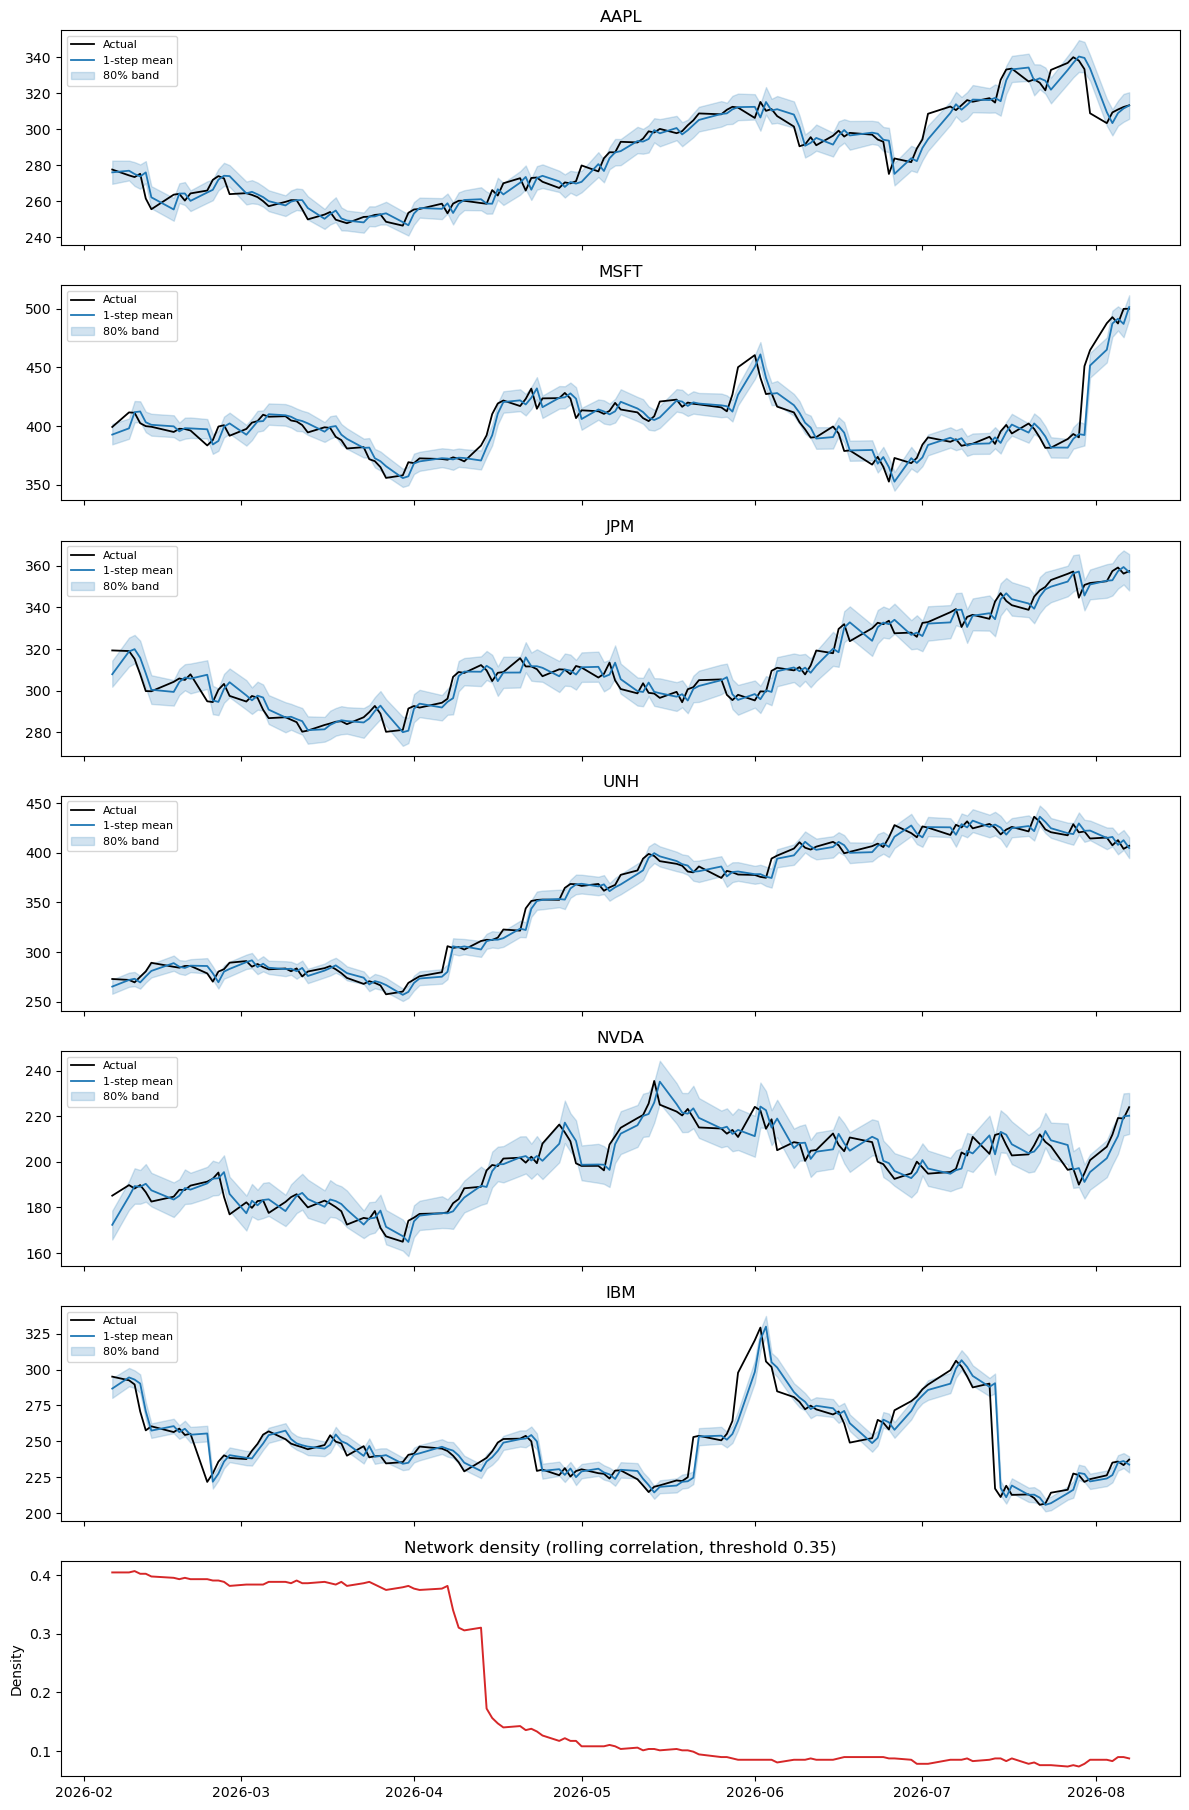

In [11]:
# ------------------------------------------------------------
# 9. Plots (prices + network density)
# ------------------------------------------------------------
plot_list = ["AAPL", "MSFT", "JPM", "UNH", "NVDA", "IBM"]
fig, axes = plt.subplots(len(plot_list)+1, 1, figsize=(12, 2.6*(len(plot_list)+1)), sharex=True)

for ax, tkr in zip(axes[:-1], plot_list):
    j = tickers.index(tkr)
    ax.plot(fc_dates, realized[:, j], color="black", lw=1.3, label="Actual")
    ax.plot(fc_dates, price_mean[:, j], color="C0", lw=1.3, label="1-step mean")
    ax.fill_between(fc_dates, price_q10[:, j], price_q90[:, j],
                    color="C0", alpha=0.2, label="80% band")
    ax.set_title(tkr)
    ax.legend(loc="upper left", fontsize=8)

axes[-1].plot(fc_dates, density, color="C3", lw=1.4)
axes[-1].set_title("Network density (rolling correlation, threshold 0.35)")
axes[-1].set_ylabel("Density")
plt.tight_layout()
plt.savefig("rolling_1step_6m_with_network.png", dpi=150)
print("  rolling_1step_6m_with_network.png")
print("\nDone.")

In [2]:
#!/usr/bin/env python3
"""
Network-based identification of important DJIA stocks
=====================================================
Implements the practical recommendations:
  - average degree
  - persistence (fraction of days connected)
  - core membership (connected ≥ 95 % of days)
  - average strength
  - simple degree-centrality trajectory summary
"""

import numpy as np
import pandas as pd
from pathlib import Path

In [3]:
# ------------------------------------------------------------
# 1. Load the saved networks
# ------------------------------------------------------------
NPZ = Path("rolling_1step_6m_with_networks.npz")
data = np.load(NPZ, allow_pickle=True)

A_series = data["A_series"]          # (H, N, N) binary adjacency
W_series = data["W_series"]          # (H, N, N) row-normalised weights
tickers  = data["tickers"]
dates    = data["dates"]

if isinstance(tickers[0], bytes):
    tickers = np.array([t.decode() for t in tickers])

H, N, _ = A_series.shape
print(f"Loaded networks: {H} days × {N} stocks")
print(f"Date range: {dates[0]} → {dates[-1]}")

Loaded networks: 126 days × 30 stocks
Date range: 2026-02-06 → 2026-08-07


In [4]:
# ------------------------------------------------------------
# 2. Basic connectivity metrics
# ------------------------------------------------------------
# Degree of each stock on each day (number of connections)
degree = A_series.sum(axis=2)                # (H, N)

# Strength (sum of weights)
strength = W_series.sum(axis=2)              # (H, N)

# Average degree and average strength over the whole window
avg_degree   = degree.mean(axis=0)
avg_strength = strength.mean(axis=0)

# Persistence = fraction of days the stock has at least one connection
persistence = (degree > 0).mean(axis=0)

# Core membership: connected on ≥ 95 % of days
core_threshold = 0.95
is_core = persistence >= core_threshold

In [5]:
# ------------------------------------------------------------
# 3. Simple centrality summary (degree centrality is already the degree)
#    We also compute a crude “rising / falling” trend
# ------------------------------------------------------------
# Linear trend of degree over time (positive = becoming more central)
t = np.arange(H)
degree_trend = np.array([np.polyfit(t, degree[:, j], 1)[0] for j in range(N)])

In [6]:
# ------------------------------------------------------------
# 4. Assemble ranking table
# ------------------------------------------------------------
df = pd.DataFrame({
    "ticker"        : tickers,
    "avg_degree"    : avg_degree,
    "avg_strength"  : avg_strength,
    "persistence"   : persistence,
    "is_core"       : is_core,
    "degree_trend"  : degree_trend
})

# Sort by a simple importance score: persistence × average degree
df["importance"] = df["persistence"] * df["avg_degree"]
df = df.sort_values("importance", ascending=False).reset_index(drop=True)
df["rank"] = np.arange(1, N + 1)

In [7]:
# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------
print("\n=== Full ranking by persistence × average degree ===")
print(df.to_string(index=False, float_format="%.3f"))

core_stocks = df[df["is_core"]]
print(f"\n=== Core stocks (connected on ≥ {core_threshold:.0%} of days) ===")
print(core_stocks[["rank", "ticker", "avg_degree", "persistence", "avg_strength"]]
      .to_string(index=False, float_format="%.3f"))

top6 = df.head(6)
print("\n=== Top 6 most important stocks ===")
print(top6[["rank", "ticker", "avg_degree", "persistence", "importance"]]
      .to_string(index=False, float_format="%.3f"))


=== Full ranking by persistence × average degree ===
ticker  avg_degree  avg_strength  persistence  is_core  degree_trend  importance  rank
   AXP      11.159         1.000        1.000     True        -0.172      11.159     1
    GS      10.198         1.000        1.000     True        -0.162      10.198     2
   HON       9.937         1.000        1.000     True        -0.161       9.937     3
   JPM       9.571         1.000        1.000     True        -0.173       9.571     4
   MMM       9.444         1.000        1.000     True        -0.166       9.444     5
   DIS       9.246         1.000        1.000     True        -0.153       9.246     6
    HD       8.770         1.000        1.000     True        -0.049       8.770     7
   SHW       8.492         1.000        1.000     True        -0.113       8.492     8
    PG       7.357         1.000        1.000     True        -0.037       7.357     9
     V       7.087         1.000        1.000     True        -0.159       7

In [8]:
# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------
df.to_csv("network_importance_ranking.csv", index=False)
core_stocks.to_csv("network_core_stocks.csv", index=False)
top6.to_csv("network_top6_stocks.csv", index=False)

print("\nSaved:")
print("  network_importance_ranking.csv")
print("  network_core_stocks.csv")
print("  network_top6_stocks.csv")


Saved:
  network_importance_ranking.csv
  network_core_stocks.csv
  network_top6_stocks.csv


In [9]:
#!/usr/bin/env python3
"""
Recommended network analysis sequence
=====================================
1. Centrality trajectories (degree + eigenvector)
2. Lead-lag test: does today’s centrality predict tomorrow’s return?
3. Intersection of network-core stocks and risk-adjusted forecast ranking
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path
from numpy.linalg import eigvals, eig

In [10]:
# ------------------------------------------------------------
# 0. Helper: eigenvector centrality (simple, robust version)
# ------------------------------------------------------------
def eigenvector_centrality(A, max_iter=100, tol=1e-6):
    """Compute eigenvector centrality of a non-negative adjacency matrix."""
    n = A.shape[0]
    x = np.ones(n) / n
    for _ in range(max_iter):
        x_new = A @ x
        norm = np.linalg.norm(x_new, 1)
        if norm == 0:
            return np.zeros(n)
        x_new /= norm
        if np.linalg.norm(x_new - x, 1) < tol:
            break
        x = x_new
    return x

In [12]:
# ------------------------------------------------------------
# 1. Load networks and price data
# ------------------------------------------------------------
NPZ_NET = Path("rolling_1step_6m_with_networks.npz")
NET = np.load(NPZ_NET, allow_pickle=True)

A_series = NET["A_series"]          # (H, N, N)
W_series = NET["W_series"]          # (H, N, N)
tickers  = NET["tickers"]
dates    = NET["dates"]

if isinstance(tickers[0], bytes):
    tickers = np.array([t.decode() for t in tickers])

H, N, _ = A_series.shape
print(f"Networks: {H} days × {N} stocks")

# Load original prices to compute realised returns
PRICE_CSV = Path("djia_adj_close_wide_10y.csv")
prices = pd.read_csv(PRICE_CSV, parse_dates=["Date"], index_col="Date")
prices = prices[tickers].ffill().dropna()

# Align returns with the network dates
# network dates correspond to the forecast origins; we need the next-day return
price_dates = prices.index
ret = np.log(prices).diff().dropna()

Networks: 126 days × 30 stocks


In [13]:
# ------------------------------------------------------------
# 2. Centrality trajectories
# ------------------------------------------------------------
degree_cent = np.zeros((H, N))
eigen_cent  = np.zeros((H, N))

for t in range(H):
    A = A_series[t]
    degree_cent[t] = A.sum(axis=1)                  # out-degree
    # use the weight matrix for eigenvector centrality (more informative)
    eigen_cent[t]  = eigenvector_centrality(W_series[t])

avg_degree_cent = degree_cent.mean(axis=0)
avg_eigen_cent  = eigen_cent.mean(axis=0)

# trend of eigenvector centrality
t_idx = np.arange(H)
eigen_trend = np.array([np.polyfit(t_idx, eigen_cent[:, j], 1)[0] for j in range(N)])

# persistence (connected ≥ 95 % of days)
persistence = (degree_cent > 0).mean(axis=0)
is_core = persistence >= 0.95

centrality_df = pd.DataFrame({
    "ticker"          : tickers,
    "avg_degree_cent" : avg_degree_cent,
    "avg_eigen_cent"  : avg_eigen_cent,
    "eigen_trend"     : eigen_trend,
    "persistence"     : persistence,
    "is_core"         : is_core
}).sort_values("avg_eigen_cent", ascending=False)

print("\n=== Centrality ranking (by average eigenvector centrality) ===")
print(centrality_df.to_string(index=False, float_format="%.4f"))


=== Centrality ranking (by average eigenvector centrality) ===
ticker  avg_degree_cent  avg_eigen_cent  eigen_trend  persistence  is_core
   JPM           9.5714          0.0398       0.0001       1.0000     True
  NVDA           5.5476          0.0398       0.0001       1.0000     True
  MSFT           4.5317          0.0398       0.0001       1.0000     True
   MRK           3.6825          0.0398       0.0001       1.0000     True
   MMM           9.4444          0.0398       0.0001       1.0000     True
   MCD           5.0794          0.0398       0.0001       1.0000     True
    KO           3.8175          0.0398       0.0001       1.0000     True
  AMGN           2.2222          0.0398       0.0001       1.0000     True
   JNJ           4.4365          0.0398       0.0001       1.0000     True
   IBM           3.0794          0.0398       0.0001       1.0000     True
   HON           9.9365          0.0398       0.0001       1.0000     True
    HD           8.7698          0.0

In [14]:
# ------------------------------------------------------------
# 3. Lead-lag test: today’s centrality → tomorrow’s return
# ------------------------------------------------------------
# Build a panel of (centrality_t, return_{t+1})
records = []
for t in range(H-1):
    # find the calendar date of this network snapshot
    d = pd.Timestamp(dates[t])
    # next trading day’s return
    future = ret.loc[d:].iloc[1:2] if d in ret.index else None
    if future is None or future.empty:
        continue
    for j, tkr in enumerate(tickers):
        if tkr not in future.columns:
            continue
        records.append({
            "date"        : d,
            "ticker"      : tkr,
            "degree_cent" : degree_cent[t, j],
            "eigen_cent"  : eigen_cent[t, j],
            "next_ret"    : future[tkr].values[0]
        })

panel = pd.DataFrame(records)
print(f"\nLead-lag panel: {len(panel)} observations")

# Simple correlation
corr_degree = panel["degree_cent"].corr(panel["next_ret"])
corr_eigen  = panel["eigen_cent"].corr(panel["next_ret"])

print(f"Correlation (degree centrality → next-day return): {corr_degree:.4f}")
print(f"Correlation (eigen centrality  → next-day return): {corr_eigen:.4f}")

# Optional: rank-bin analysis
panel["eigen_bin"] = pd.qcut(panel["eigen_cent"], 5, labels=False, duplicates="drop")
bin_means = panel.groupby("eigen_bin")["next_ret"].mean()
print("\nAverage next-day return by eigenvector-centrality quintile:")
print(bin_means)


Lead-lag panel: 3750 observations
Correlation (degree centrality → next-day return): -0.0445
Correlation (eigen centrality  → next-day return): -0.0095

Average next-day return by eigenvector-centrality quintile:
eigen_bin
0    0.000335
1   -0.001325
2    0.001045
3   -0.000482
4    0.002991
Name: next_ret, dtype: float64


In [15]:
# ------------------------------------------------------------
# 4. Intersection with risk-adjusted forecast ranking
# ------------------------------------------------------------
# Try to load the earlier risk-adjusted ranking; if missing, create a placeholder
RANK_CSV = Path("djia_risk_adjusted_ranking.csv")
if RANK_CSV.exists():
    risk_rank = pd.read_csv(RANK_CSV)
    risk_rank = risk_rank.rename(columns={"ticker": "ticker"})
    print("\nLoaded risk-adjusted ranking from", RANK_CSV)
else:
    print("\nRisk-adjusted ranking file not found – skipping intersection.")
    risk_rank = None

if risk_rank is not None:
    # keep top-10 from each ranking
    top_network = set(centrality_df.head(10)["ticker"])
    top_risk    = set(risk_rank.head(10)["ticker"])
    intersection = top_network & top_risk

    print("\n=== Intersection of top-10 network & top-10 risk-adjusted ===")
    if intersection:
        for tkr in sorted(intersection):
            print(" ", tkr)
    else:
        print("  (empty)")

    # richer join
    merged = centrality_df.merge(
        risk_rank[["ticker", "risk_adj_score", "rank"]].rename(columns={"rank": "risk_rank"}),
        on="ticker", how="left"
    )
    merged = merged.sort_values("avg_eigen_cent", ascending=False)
    merged.to_csv("network_plus_risk_ranking.csv", index=False)
    print("\nSaved: network_plus_risk_ranking.csv")


Loaded risk-adjusted ranking from djia_risk_adjusted_ranking.csv

=== Intersection of top-10 network & top-10 risk-adjusted ===
  JPM
  MCD
  MSFT
  NVDA

Saved: network_plus_risk_ranking.csv


In [16]:
# ------------------------------------------------------------
# 5. Save centrality results
# ------------------------------------------------------------
centrality_df.to_csv("centrality_trajectories_summary.csv", index=False)
np.savez_compressed(
    "centrality_trajectories.npz",
    degree_cent=degree_cent,
    eigen_cent=eigen_cent,
    tickers=tickers,
    dates=dates
)

print("\nSaved:")
print("  centrality_trajectories_summary.csv")
print("  centrality_trajectories.npz")
print("\nDone.")


Saved:
  centrality_trajectories_summary.csv
  centrality_trajectories.npz

Done.
